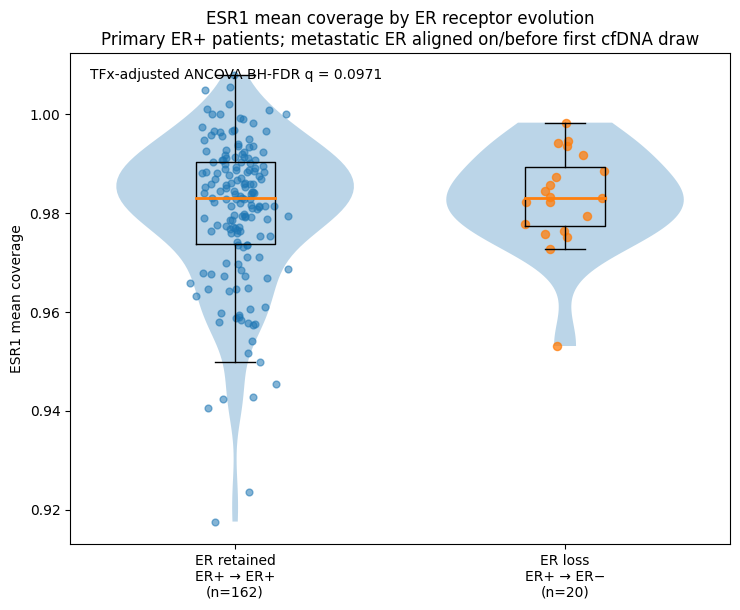

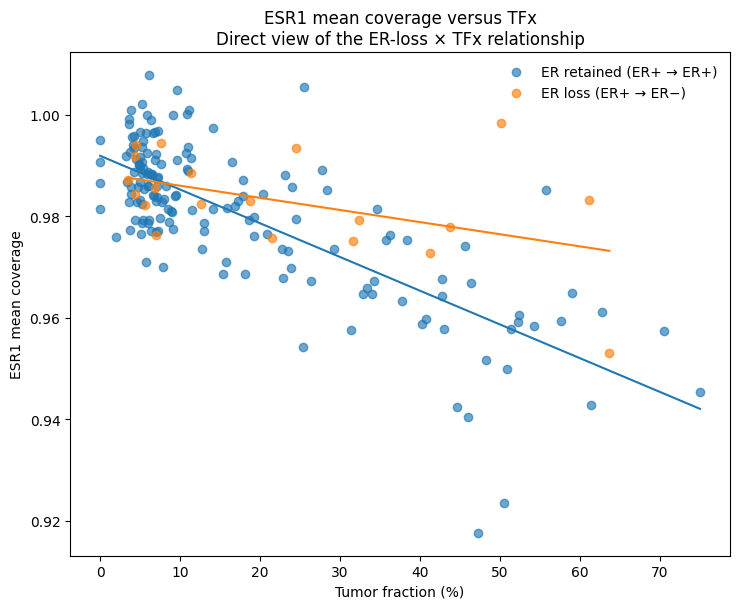

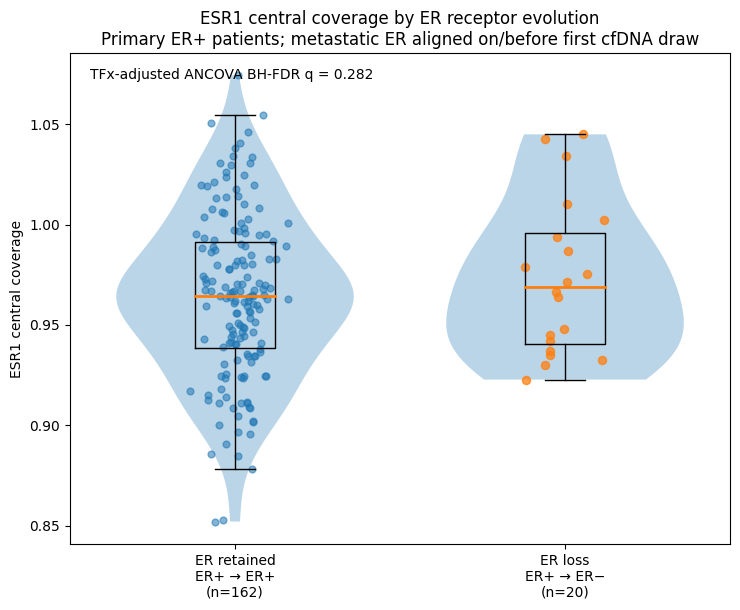

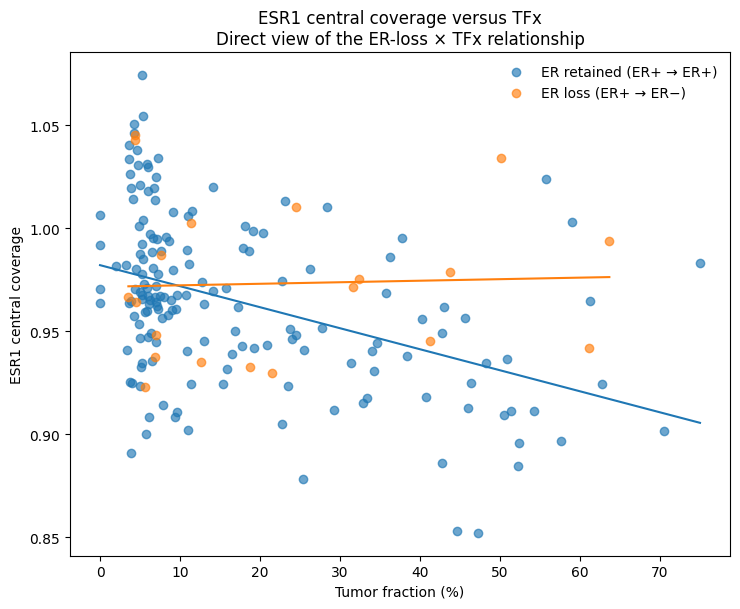

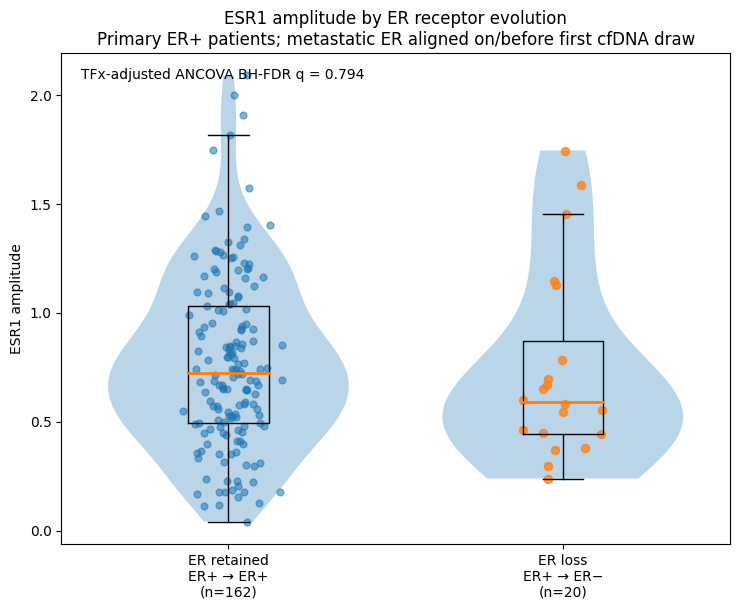

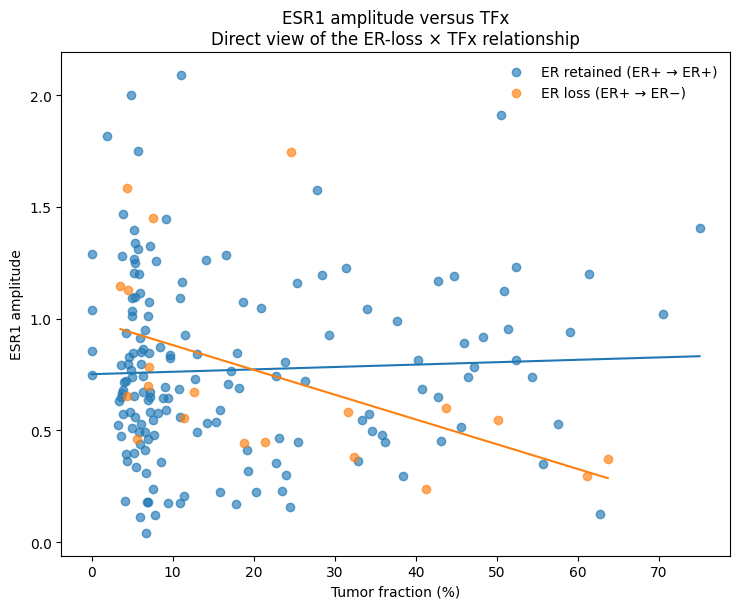

AURORA direct ESR1 TFBS analysis: ER retained vs ER loss

PRIMARY COHORT
--------------
Primary ER-positive patients with clinically documented metastatic ER status known on/before the first cfDNA draw.
Total n=182
ER retained n=162
ER loss n=20

PRIMARY ANCOVA RESULTS (TFx-adjusted; HC3; BH-FDR across 3 ESR1 metrics)
------------------------------------------------------------------------
ESR1 mean coverage: beta(loss-retained)=0.005903; p=0.0323597; q=0.0970791
ESR1 central coverage: beta(loss-retained)=0.013650; p=0.187912; q=0.281867
ESR1 amplitude: beta(loss-retained)=-0.027585; p=0.793826; q=0.793826

GENERALIZED ANCOVA / EQUAL-SLOPE CHECK
--------------------------------------
ESR1 mean coverage: interaction p=0.0264475, interaction q=0.0396712; joint Wald p=0.0320331, joint q=0.0368918
ESR1 central coverage: interaction p=0.03996, interaction q=0.03996; joint Wald p=0.0368918, joint q=0.0368918
ESR1 amplitude: interaction p=0.00126745, interaction q=0.00380234; joint Wald p=0.0

In [4]:
#!/usr/bin/env python3
"""
AURORA Griffin: direct ESR1 TFBS analysis in ER-retained vs ER-loss patients
===========================================================================

Primary biological question
---------------------------
Among patients whose primary tumor was ER-positive, does the first-draw cfDNA
Griffin signal at ESR1 TFBS differ between:

    ER retained: primary ER+ -> blood-aligned metastatic ER+
    ER loss:     primary ER+ -> blood-aligned metastatic ER-

The metastatic ER status used for the PRIMARY analysis is the clinically
documented status known on or before the selected first cfDNA draw. This keeps
the receptor phenotype temporally aligned to the plasma Griffin measurement.

Why this analysis?
------------------
The predictive models can obscure the underlying data. This analysis shows
the direct patient-level ESR1 mean coverage, central coverage, and amplitude.

Statistical strategy
--------------------
1. Raw descriptive comparison:
   - violin + box + individual patient points
   - medians/IQR
   - Mann-Whitney U test as a distribution-free descriptive sensitivity test

2. Original-study-aligned primary inference:
   - ANCOVA-like linear model:
       ESR1 feature ~ ER_loss + TFx
   - HC3 robust standard errors
   - BH-FDR across the 3 prespecified ESR1 metrics

3. Fully adjusted sensitivity:
       ESR1 feature ~ ER_loss + TFx + HER2 + primary histology
   - HC3 robust SE
   - BH-FDR across 3 metrics

4. ANCOVA slope-assumption check:
       ESR1 feature ~ ER_loss * TFx + HER2 + primary histology
   - TFx is centered
   - HC3 robust SE
   - tests ER_loss x TFx interaction
   - robust joint 2-df Wald test of ER_loss + interaction
   - BH-FDR across 3 metrics

   If the interaction is significant, a single constant ANCOVA group effect
   is an oversimplification: the ER-loss difference varies with TFx.

5. Modeling-cohort endpoint sensitivity:
   - Repeat the simpler ANCOVA using earliest metastatic ER from the 241-patient
     modeling cohort, irrespective of timing relative to the blood draw.
   - This is included only to connect the direct plot with the model endpoint.

Seed
----
All random jitter uses SEED = 1234 for reproducibility.
"""

from __future__ import annotations

import argparse
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as st
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests


SEED = 1234

ESR1_METRICS = [
    "ESR1_mean_coverage",
    "ESR1_central_coverage",
    "ESR1_amplitude",
]

DISPLAY = {
    "ESR1_mean_coverage": "ESR1 mean coverage",
    "ESR1_central_coverage": "ESR1 central coverage",
    "ESR1_amplitude": "ESR1 amplitude",
}


def parse_args():
    p = argparse.ArgumentParser()
    p.add_argument(
        "--firstdraw",
        default=(
            "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Griffin/Downstream/AURORA_Griffin_Met_ER_FirstDraw_TFBS"
            "/First_draw_blood_aligned_metastatic_ER_dataset.tsv"
        ),
    )
    p.add_argument(
        "--split",
        default="/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Griffin/Downstream/AURORA_Griffin_Heldout_Test_ER/Cohort_split.tsv",
    )
    p.add_argument(
        "--outdir",
        default="/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Griffin/Downstream/AURORA_ESR1_ER_loss_direct_analysis",
    )
    p.add_argument("--seed", type=int, default=SEED)
    p.add_argument("--dpi", type=int, default=300)
    return p.parse_args(args=[])


def bh(values):
    return multipletests(np.asarray(values, dtype=float), method="fdr_bh")[1]


def rank_biserial_from_u(u, n_loss, n_retained):
    return 2.0 * u / (n_loss * n_retained) - 1.0


def iqr(values):
    q1, q3 = np.percentile(values, [25, 75])
    return float(q1), float(q3)


def fit_standard_ancova(data, outcome, full_adjustment=False):
    if full_adjustment:
        formula = f"{outcome} ~ ER_loss + TFx_pct + C(HER2) + C(histology)"
    else:
        formula = f"{outcome} ~ ER_loss + TFx_pct"

    fit = smf.ols(formula, data=data).fit(cov_type="HC3")
    ci = fit.conf_int().loc["ER_loss"]

    return {
        "n_model": int(fit.nobs),
        "beta_ER_loss": float(fit.params["ER_loss"]),
        "HC3_SE": float(fit.bse["ER_loss"]),
        "CI95_low": float(ci.iloc[0]),
        "CI95_high": float(ci.iloc[1]),
        "p_ER_loss": float(fit.pvalues["ER_loss"]),
    }


def fit_generalized_ancova(data, outcome):
    d = data.dropna(
        subset=[outcome, "TFx_pct", "HER2", "histology", "ER_loss"]
    ).copy()
    mean_tfx = float(d["TFx_pct"].mean())
    d["TFx_centered"] = d["TFx_pct"] - mean_tfx

    formula = (
        f"{outcome} ~ ER_loss * TFx_centered + C(HER2) + C(histology)"
    )
    fit = smf.ols(formula, data=d).fit(cov_type="HC3")

    # ER-loss contrast at the mean TFx because TFx is centered.
    ci = fit.conf_int().loc["ER_loss"]

    # Robust 2-df joint Wald test:
    # H0: ER_loss = 0 AND ER_loss:TFx_centered = 0
    names = list(fit.params.index)
    R = np.zeros((2, len(names)))
    R[0, names.index("ER_loss")] = 1.0
    R[1, names.index("ER_loss:TFx_centered")] = 1.0
    wald = fit.wald_test(R, scalar=True)

    return {
        "n_model": int(fit.nobs),
        "mean_TFx_pct": mean_tfx,
        "contrast_at_mean_TFx": float(fit.params["ER_loss"]),
        "contrast_HC3_SE": float(fit.bse["ER_loss"]),
        "contrast_CI95_low": float(ci.iloc[0]),
        "contrast_CI95_high": float(ci.iloc[1]),
        "contrast_p": float(fit.pvalues["ER_loss"]),
        "interaction_beta": float(fit.params["ER_loss:TFx_centered"]),
        "interaction_p": float(fit.pvalues["ER_loss:TFx_centered"]),
        "joint_Wald_chi2": float(wald.statistic),
        "joint_Wald_p": float(wald.pvalue),
    }


def save_violin_box_points(data, outcome, outdir, seed, dpi, ancova_q):
    rng = np.random.default_rng(seed)

    retained = data.loc[data["ER_loss"] == 0, outcome].dropna().to_numpy()
    loss = data.loc[data["ER_loss"] == 1, outcome].dropna().to_numpy()

    fig, ax = plt.subplots(figsize=(7.5, 6.2))

    ax.violinplot(
        [retained, loss],
        positions=[1, 2],
        widths=0.72,
        showmeans=False,
        showmedians=False,
        showextrema=False,
    )
    ax.boxplot(
        [retained, loss],
        positions=[1, 2],
        widths=0.24,
        showfliers=False,
        medianprops={"linewidth": 2},
    )

    jitter_ret = rng.normal(1, 0.055, len(retained))
    jitter_loss = rng.normal(2, 0.055, len(loss))
    ax.scatter(jitter_ret, retained, s=24, alpha=0.55)
    ax.scatter(jitter_loss, loss, s=34, alpha=0.75)

    ax.set_xticks(
        [1, 2],
        [
            f"ER retained\nER+ → ER+\n(n={len(retained)})",
            f"ER loss\nER+ → ER−\n(n={len(loss)})",
        ],
    )
    ax.set_ylabel(DISPLAY[outcome])
    ax.set_title(
        f"{DISPLAY[outcome]} by ER receptor evolution\n"
        "Primary ER+ patients; metastatic ER aligned on/before first cfDNA draw"
    )
    ax.text(
        0.03,
        0.97,
        f"TFx-adjusted ANCOVA BH-FDR q = {ancova_q:.3g}",
        transform=ax.transAxes,
        va="top",
    )
    fig.tight_layout()

    stem = outcome.replace("ESR1_", "")
    png = outdir / f"ESR1_{stem}_ER_retained_vs_loss_violin_box_points.png"
    pdf = outdir / f"ESR1_{stem}_ER_retained_vs_loss_violin_box_points.pdf"
    fig.savefig(png, dpi=dpi, bbox_inches="tight")
    fig.savefig(pdf, bbox_inches="tight")
    plt.show()
    plt.close(fig)


def save_tfx_interaction_plot(data, outcome, outdir, dpi):
    d = data.dropna(subset=[outcome, "TFx_pct", "ER_loss"]).copy()

    fig, ax = plt.subplots(figsize=(7.5, 6.2))

    for group_value, label in [
        (0, "ER retained (ER+ → ER+)"),
        (1, "ER loss (ER+ → ER−)"),
    ]:
        g = d[d["ER_loss"] == group_value]
        ax.scatter(g["TFx_pct"], g[outcome], alpha=0.65, label=label)

        if len(g) >= 2:
            slope, intercept = np.polyfit(g["TFx_pct"], g[outcome], 1)
            x_line = np.linspace(
                float(g["TFx_pct"].min()),
                float(g["TFx_pct"].max()),
                100,
            )
            ax.plot(x_line, intercept + slope * x_line)

    ax.set_xlabel("Tumor fraction (%)")
    ax.set_ylabel(DISPLAY[outcome])
    ax.set_title(
        f"{DISPLAY[outcome]} versus TFx\n"
        "Direct view of the ER-loss × TFx relationship"
    )
    ax.legend(frameon=False)
    fig.tight_layout()

    stem = outcome.replace("ESR1_", "")
    fig.savefig(
        outdir / f"ESR1_{stem}_TFx_interaction.png",
        dpi=dpi,
        bbox_inches="tight",
    )
    fig.savefig(
        outdir / f"ESR1_{stem}_TFx_interaction.pdf",
        bbox_inches="tight",
    )
    plt.show()
    plt.close(fig)


def main():
    args = parse_args()
    firstdraw_path = Path(args.firstdraw)
    split_path = Path(args.split)
    outdir = Path(args.outdir)
    outdir.mkdir(parents=True, exist_ok=True)

    firstdraw = pd.read_csv(firstdraw_path, sep="\t")
    split = pd.read_csv(split_path, sep="\t")

    required_firstdraw = [
        "patient_id", "sample", "ER", "TFx_pct", "HER2", "histology",
        *ESR1_METRICS,
    ]
    required_split = [
        "patient_id", "sample", "Primary_tumor_ER", "Earliest_metastatic_ER",
    ]

    missing = [c for c in required_firstdraw if c not in firstdraw.columns]
    if missing:
        raise KeyError(f"First-draw file is missing: {missing}")
    missing = [c for c in required_split if c not in split.columns]
    if missing:
        raise KeyError(f"Split file is missing: {missing}")

    merged = split.merge(
        firstdraw,
        on=["patient_id", "sample"],
        how="left",
        validate="one_to_one",
    )

    # ------------------------------------------------------------------
    # PRIMARY COHORT:
    # primary ER+ and a metastatic ER result known on/before first cfDNA.
    # ------------------------------------------------------------------
    direct = merged[
        (merged["Primary_tumor_ER"] == "Positive")
        & (merged["ER"].isin(["Positive", "Negative"]))
    ].copy()

    direct["ER_loss"] = (direct["ER"] == "Negative").astype(int)
    direct["switch_group"] = np.where(
        direct["ER_loss"] == 1,
        "ER loss (primary ER+ -> aligned metastatic ER-)",
        "ER retained (primary ER+ -> aligned metastatic ER+)",
    )

    # Keep a patient-level analysis table.
    direct_cols = [
        "patient_id", "sample", "set",
        "Primary_tumor_ER", "Earliest_metastatic_ER",
        "ER", "ER_source_day", "ER_lag_days",
        "ER_loss", "switch_group",
        "TFx_pct", "HER2", "histology",
        *ESR1_METRICS,
    ]
    direct[direct_cols].to_csv(
        outdir / "ESR1_primary_ERpositive_blood_aligned_patient_level.tsv",
        sep="\t",
        index=False,
    )

    # Cohort counts.
    counts = pd.DataFrame(
        [
            {
                "analysis": "Primary temporally aligned direct analysis",
                "group": "ER retained (ER+ -> ER+)",
                "n": int((direct["ER_loss"] == 0).sum()),
            },
            {
                "analysis": "Primary temporally aligned direct analysis",
                "group": "ER loss (ER+ -> ER-)",
                "n": int((direct["ER_loss"] == 1).sum()),
            },
            {
                "analysis": "Model endpoint sensitivity",
                "group": "ER retained using earliest metastatic ER",
                "n": int(
                    (
                        (merged["Primary_tumor_ER"] == "Positive")
                        & (merged["Earliest_metastatic_ER"] == "Positive")
                    ).sum()
                ),
            },
            {
                "analysis": "Model endpoint sensitivity",
                "group": "ER loss using earliest metastatic ER",
                "n": int(
                    (
                        (merged["Primary_tumor_ER"] == "Positive")
                        & (merged["Earliest_metastatic_ER"] == "Negative")
                    ).sum()
                ),
            },
        ]
    )
    counts.to_csv(outdir / "ER_switch_cohort_counts.tsv", sep="\t", index=False)

    # ------------------------------------------------------------------
    # Raw descriptive + standard ANCOVA.
    # ------------------------------------------------------------------
    raw_ancova_rows = []
    for outcome in ESR1_METRICS:
        retained = direct.loc[direct["ER_loss"] == 0, outcome].dropna().to_numpy()
        loss = direct.loc[direct["ER_loss"] == 1, outcome].dropna().to_numpy()

        retained_q1, retained_q3 = iqr(retained)
        loss_q1, loss_q3 = iqr(loss)

        mw = st.mannwhitneyu(loss, retained, alternative="two-sided")
        welch = st.ttest_ind(loss, retained, equal_var=False)

        standard = fit_standard_ancova(direct, outcome, full_adjustment=False)
        full = fit_standard_ancova(direct, outcome, full_adjustment=True)

        raw_ancova_rows.append(
            {
                "metric": outcome,
                "n_retained": len(retained),
                "n_ER_loss": len(loss),
                "retained_mean": float(np.mean(retained)),
                "ER_loss_mean": float(np.mean(loss)),
                "raw_mean_difference_loss_minus_retained":
                    float(np.mean(loss) - np.mean(retained)),
                "retained_median": float(np.median(retained)),
                "retained_Q1": retained_q1,
                "retained_Q3": retained_q3,
                "ER_loss_median": float(np.median(loss)),
                "ER_loss_Q1": loss_q1,
                "ER_loss_Q3": loss_q3,
                "Mann_Whitney_U": float(mw.statistic),
                "Mann_Whitney_p": float(mw.pvalue),
                "rank_biserial_loss_vs_retained":
                    float(rank_biserial_from_u(
                        mw.statistic, len(loss), len(retained)
                    )),
                "Welch_p": float(welch.pvalue),
                "ANCOVA_model": "feature ~ ER_loss + TFx",
                "ANCOVA_n": standard["n_model"],
                "ANCOVA_beta_ER_loss": standard["beta_ER_loss"],
                "ANCOVA_HC3_SE": standard["HC3_SE"],
                "ANCOVA_CI95_low": standard["CI95_low"],
                "ANCOVA_CI95_high": standard["CI95_high"],
                "ANCOVA_p": standard["p_ER_loss"],
                "Full_model": (
                    "feature ~ ER_loss + TFx + HER2 + primary histology"
                ),
                "Full_n": full["n_model"],
                "Full_beta_ER_loss": full["beta_ER_loss"],
                "Full_HC3_SE": full["HC3_SE"],
                "Full_CI95_low": full["CI95_low"],
                "Full_CI95_high": full["CI95_high"],
                "Full_p": full["p_ER_loss"],
            }
        )

    raw_ancova = pd.DataFrame(raw_ancova_rows)
    raw_ancova["Mann_Whitney_BH_FDR_q"] = bh(raw_ancova["Mann_Whitney_p"])
    raw_ancova["ANCOVA_BH_FDR_q"] = bh(raw_ancova["ANCOVA_p"])
    raw_ancova["Full_BH_FDR_q"] = bh(raw_ancova["Full_p"])
    raw_ancova.to_csv(
        outdir / "ESR1_direct_raw_and_ANCOVA_results.tsv",
        sep="\t",
        index=False,
    )

    # ------------------------------------------------------------------
    # Generalized ANCOVA with TFx interaction.
    # ------------------------------------------------------------------
    interaction_rows = []
    for outcome in ESR1_METRICS:
        result = fit_generalized_ancova(direct, outcome)
        interaction_rows.append(
            {
                "metric": outcome,
                "model": (
                    "feature ~ ER_loss * centered_TFx + HER2 + primary histology"
                ),
                **result,
            }
        )

    interaction = pd.DataFrame(interaction_rows)
    interaction["contrast_BH_FDR_q"] = bh(interaction["contrast_p"])
    interaction["interaction_BH_FDR_q"] = bh(interaction["interaction_p"])
    interaction["joint_Wald_BH_FDR_q"] = bh(interaction["joint_Wald_p"])
    interaction.to_csv(
        outdir / "ESR1_generalized_ANCOVA_TFx_interaction_results.tsv",
        sep="\t",
        index=False,
    )

    # ------------------------------------------------------------------
    # Model-endpoint sensitivity: earliest metastatic ER, irrespective of timing.
    # ------------------------------------------------------------------
    model_endpoint = merged[
        merged["Primary_tumor_ER"] == "Positive"
    ].copy()
    model_endpoint["ER_loss"] = (
        model_endpoint["Earliest_metastatic_ER"] == "Negative"
    ).astype(int)

    sensitivity_rows = []
    for outcome in ESR1_METRICS:
        standard = fit_standard_ancova(
            model_endpoint, outcome, full_adjustment=False
        )
        retained = model_endpoint.loc[
            model_endpoint["ER_loss"] == 0, outcome
        ].dropna()
        loss = model_endpoint.loc[
            model_endpoint["ER_loss"] == 1, outcome
        ].dropna()

        sensitivity_rows.append(
            {
                "metric": outcome,
                "n_retained": len(retained),
                "n_ER_loss": len(loss),
                "retained_mean": float(retained.mean()),
                "ER_loss_mean": float(loss.mean()),
                "ANCOVA_beta_ER_loss": standard["beta_ER_loss"],
                "ANCOVA_HC3_SE": standard["HC3_SE"],
                "ANCOVA_CI95_low": standard["CI95_low"],
                "ANCOVA_CI95_high": standard["CI95_high"],
                "ANCOVA_p": standard["p_ER_loss"],
            }
        )

    sensitivity = pd.DataFrame(sensitivity_rows)
    sensitivity["ANCOVA_BH_FDR_q"] = bh(sensitivity["ANCOVA_p"])
    sensitivity.to_csv(
        outdir / "ESR1_earliest_metastatic_ER_model_endpoint_sensitivity.tsv",
        sep="\t",
        index=False,
    )

    # ------------------------------------------------------------------
    # Plots.
    # ------------------------------------------------------------------
    for outcome in ESR1_METRICS:
        qval = float(
            raw_ancova.loc[
                raw_ancova["metric"] == outcome,
                "ANCOVA_BH_FDR_q",
            ].iloc[0]
        )
        save_violin_box_points(
            direct, outcome, outdir, args.seed, args.dpi, qval
        )
        save_tfx_interaction_plot(direct, outcome, outdir, args.dpi)

    # ------------------------------------------------------------------
    # Summary / metadata.
    # ------------------------------------------------------------------
    metadata = {
        "seed": args.seed,
        "firstdraw_file": str(firstdraw_path),
        "split_file": str(split_path),
        "primary_analysis_n": len(direct),
        "primary_ER_retained_n": int((direct["ER_loss"] == 0).sum()),
        "primary_ER_loss_n": int((direct["ER_loss"] == 1).sum()),
        "model_endpoint_primary_ERpositive_n": len(model_endpoint),
        "model_endpoint_retained_n": int(
            (model_endpoint["ER_loss"] == 0).sum()
        ),
        "model_endpoint_loss_n": int(
            (model_endpoint["ER_loss"] == 1).sum()
        ),
    }
    (outdir / "run_metadata.json").write_text(
        json.dumps(metadata, indent=2),
        encoding="utf-8",
    )

    summary_lines = [
        "AURORA direct ESR1 TFBS analysis: ER retained vs ER loss",
        "=======================================================",
        "",
        "PRIMARY COHORT",
        "--------------",
        (
            "Primary ER-positive patients with clinically documented metastatic "
            "ER status known on/before the first cfDNA draw."
        ),
        f"Total n={len(direct)}",
        f"ER retained n={(direct['ER_loss'] == 0).sum()}",
        f"ER loss n={(direct['ER_loss'] == 1).sum()}",
        "",
        "PRIMARY ANCOVA RESULTS (TFx-adjusted; HC3; BH-FDR across 3 ESR1 metrics)",
        "------------------------------------------------------------------------",
    ]

    for _, row in raw_ancova.iterrows():
        summary_lines.append(
            f"{DISPLAY[row['metric']]}: "
            f"beta(loss-retained)={row['ANCOVA_beta_ER_loss']:.6f}; "
            f"p={row['ANCOVA_p']:.6g}; "
            f"q={row['ANCOVA_BH_FDR_q']:.6g}"
        )

    summary_lines += [
        "",
        "GENERALIZED ANCOVA / EQUAL-SLOPE CHECK",
        "--------------------------------------",
    ]
    for _, row in interaction.iterrows():
        summary_lines.append(
            f"{DISPLAY[row['metric']]}: "
            f"interaction p={row['interaction_p']:.6g}, "
            f"interaction q={row['interaction_BH_FDR_q']:.6g}; "
            f"joint Wald p={row['joint_Wald_p']:.6g}, "
            f"joint q={row['joint_Wald_BH_FDR_q']:.6g}"
        )

    summary_lines += [
        "",
        "INTERPRETATION",
        "--------------",
        (
            "The raw violin/box/point distributions do not show a strong simple "
            "ER-loss versus retained separation. In the TFx-adjusted standard "
            "ANCOVA, ESR1 mean coverage is nominally associated with ER loss but "
            "does not remain significant after BH-FDR across the three ESR1 "
            "metrics. Central coverage and amplitude are not significant."
        ),
        (
            "However, the ER-loss x TFx interaction is non-negligible, indicating "
            "that the difference between ER-loss and retained cases varies with "
            "tumor fraction. Therefore a single constant ANCOVA group effect is "
            "an oversimplification for these data. The interaction result should "
            "be treated as exploratory because the ER-loss subgroup is small."
        ),
        "",
        "MODEL-ENDPOINT SENSITIVITY",
        "--------------------------",
        (
            "Using earliest metastatic ER (the 241-patient modeling endpoint) "
            "produces a primary-ER-positive subgroup of "
            f"n={len(model_endpoint)}: retained n="
            f"{(model_endpoint['ER_loss'] == 0).sum()}, loss n="
            f"{(model_endpoint['ER_loss'] == 1).sum()}."
        ),
    ]

    (outdir / "ESR1_ER_loss_analysis_summary.txt").write_text(
        "\n".join(summary_lines) + "\n",
        encoding="utf-8",
    )

    print("\n".join(summary_lines))
    print(f"\nOutputs written to {outdir}")


if __name__ == "__main__":
    main()